In [ ]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving ClosingStockPrices.xlsx to ClosingStockPrices.xlsx


In [ ]:
# Load Excel dataset

df = pd.read_excel(
    "ClosingStockPrices.xlsx",
    sheet_name="Data",
    header=2
)

# Display first five rows
display(df.head())

,Date,IBM,INTC,CSCO,GE,DJ Industrials \nIndex
0,2010-09-03 00:00:00,127.58,18.43,21.04,15.392,10447.93
1,2010-09-07 00:00:00,125.95,18.12,20.58,15.44,10340.69
2,2010-09-08 00:00:00,126.08,17.9,20.64,15.7,10387.01
3,2010-09-09 00:00:00,126.36,18,20.61,15.91,10415.24
4,2010-09-10 00:00:00,127.99,17.97,20.62,15.98,10462.77


In [ ]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and missing values
print("\nDataset Information:")
df.info()

# Statistical summary
display(df.describe())

Dataset Shape: (35, 6)

Column Names:
['Date', 'IBM', 'INTC', 'CSCO', 'GE', 'DJ Industrials \nIndex']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   24 non-null     object
 1   IBM                    32 non-null     object
 2   INTC                   27 non-null     object
 3   CSCO                   27 non-null     object
 4   GE                     27 non-null     object
 5   DJ Industrials 
Index  27 non-null     object
dtypes: object(6)
memory usage: 1.8+ KB


,Date,IBM,INTC,CSCO,GE,DJ Industrials \nIndex
count,24,32.00,27.00,27.000,27.00,27.00
unique,24,32.00,26.00,26.000,25.00,27.00
top,2010-09-03 00:00:00,127.58,18.81,21.863,16.25,10447.93
freq,1,1.00,2.00,2.000,2.00,1.00


In [ ]:
# Remove completely empty columns
df.dropna(axis=1, how="all", inplace=True)

# Clean column names
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
)

# Convert date column
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

# Remove rows with invalid dates
df.dropna(subset=["Date"], inplace=True)

# Sort observations chronologically
df.sort_values("Date", inplace=True)

# Remove duplicate dates
df.drop_duplicates(subset=["Date"], inplace=True)

# Define stock columns
stocks = ["IBM", "INTC", "CSCO", "GE"]

# Convert stock prices to numeric values
for stock in stocks:
    df[stock] = pd.to_numeric(
        df[stock],
        errors="coerce"
    )

# Display cleaned data
display(df.head())

print("Missing Values:")
print(df.isnull().sum())

,Date,IBM,INTC,CSCO,GE,DJ Industrials Index
0,2010-09-03,127.58,18.43,21.04,15.392,10447.93
1,2010-09-07,125.95,18.12,20.58,15.440,10340.69
2,2010-09-08,126.08,17.90,20.64,15.700,10387.01
3,2010-09-09,126.36,18.00,20.61,15.910,10415.24
4,2010-09-10,127.99,17.97,20.62,15.980,10462.77


Missing Values:
Date                     0
IBM                      0
INTC                     0
CSCO                     0
GE                       0
DJ Industrials  Index    0
dtype: int64


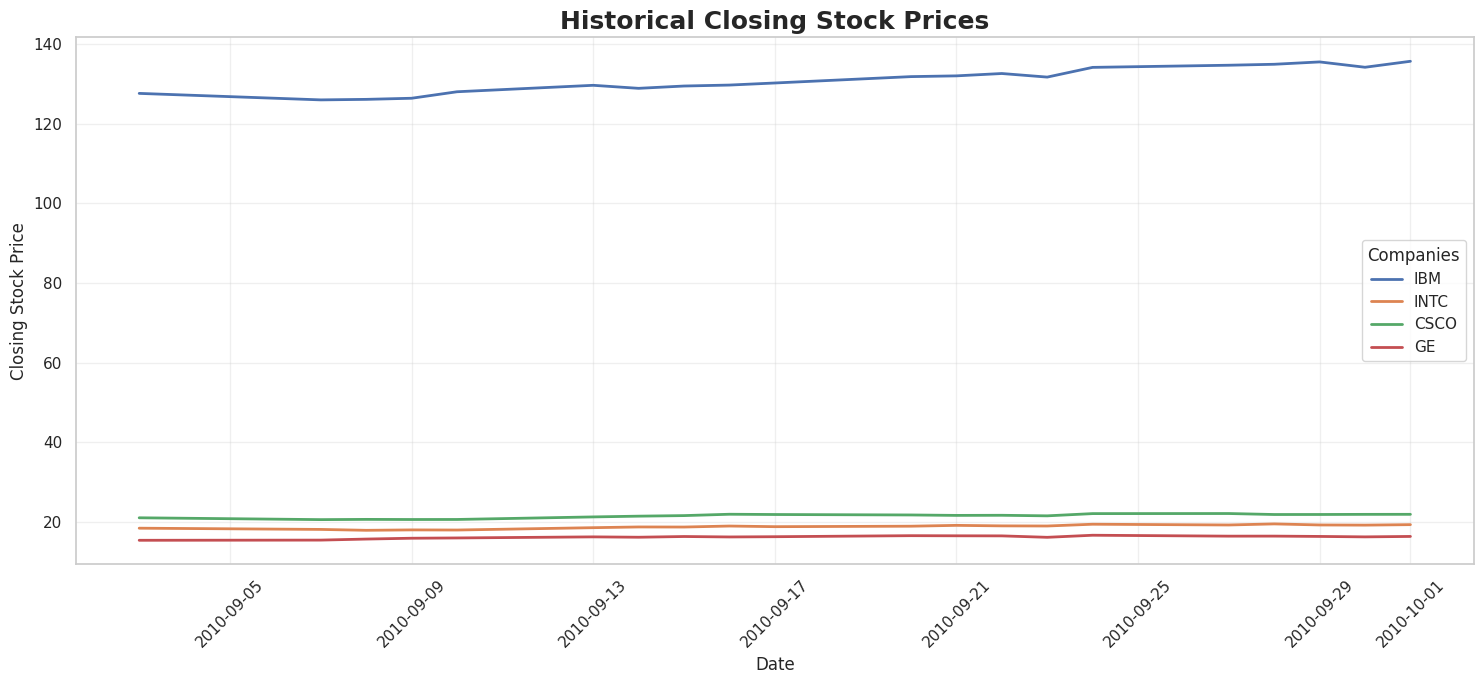

In [ ]:
plt.figure(figsize=(15, 7))

for stock in stocks:
    plt.plot(
        df["Date"],
        df[stock],
        label=stock,
        linewidth=2
    )

plt.title(
    "Historical Closing Stock Prices",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Closing Stock Price")

plt.legend(title="Companies")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

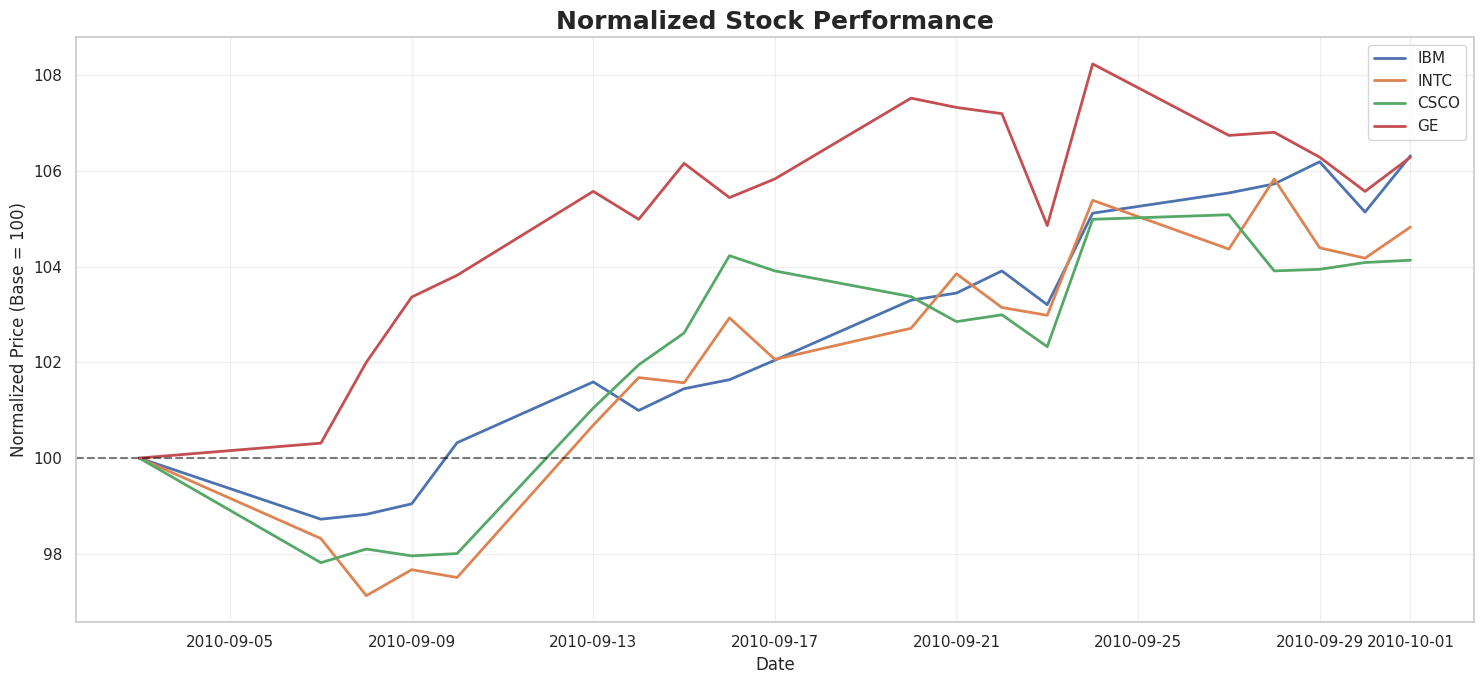

In [ ]:
# Create a date-indexed dataset
price_data = df.set_index("Date")[stocks].copy()

# Normalize each stock to a starting value of 100
normalized = price_data.div(
    price_data.apply(lambda col: col.dropna().iloc[0])
) * 100

plt.figure(figsize=(15, 7))

for stock in stocks:
    plt.plot(
        normalized.index,
        normalized[stock],
        label=stock,
        linewidth=2
    )

plt.axhline(
    100,
    color="black",
    linestyle="--",
    alpha=0.5
)

plt.title(
    "Normalized Stock Performance",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Normalized Price (Base = 100)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

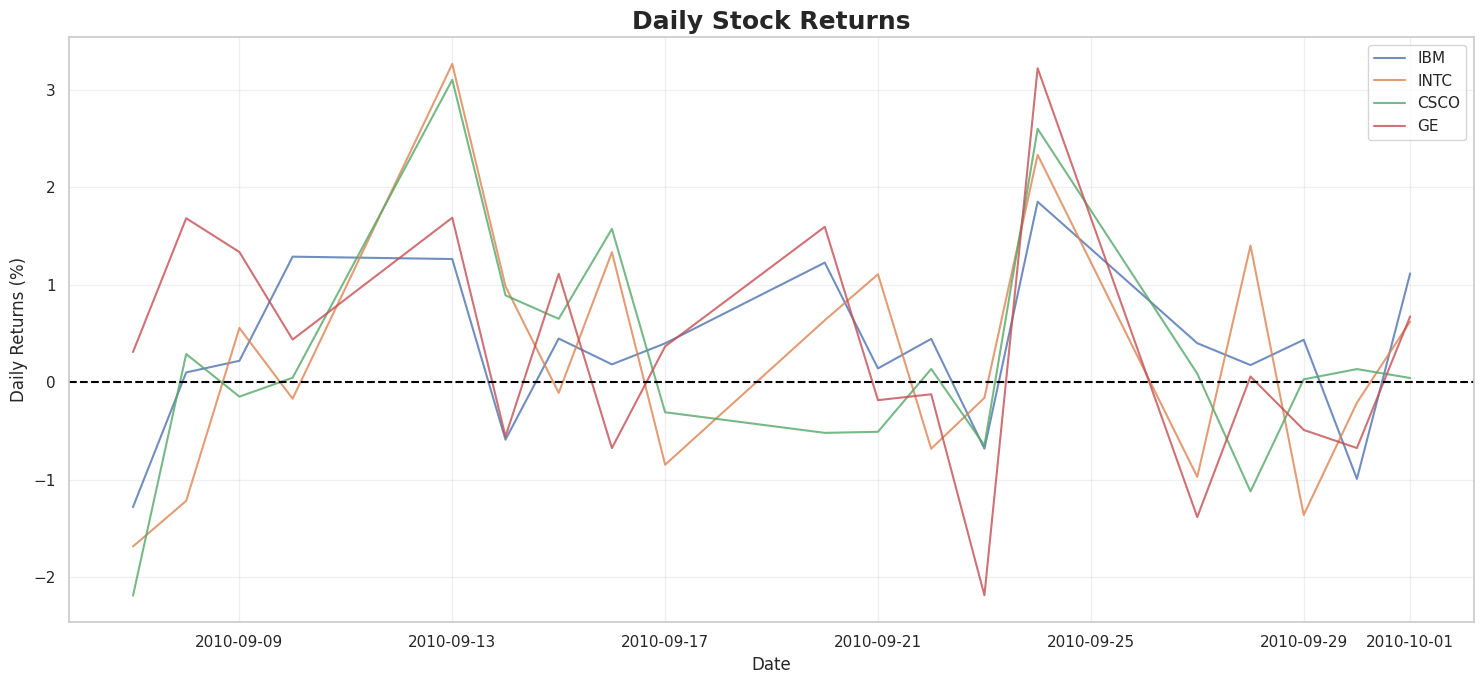

In [ ]:
# Calculate daily percentage returns
returns = price_data.pct_change(
    fill_method=None
) * 100

plt.figure(figsize=(15, 7))

for stock in stocks:
    plt.plot(
        returns.index,
        returns[stock],
        label=stock,
        alpha=0.8
    )

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.title(
    "Daily Stock Returns",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Daily Returns (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

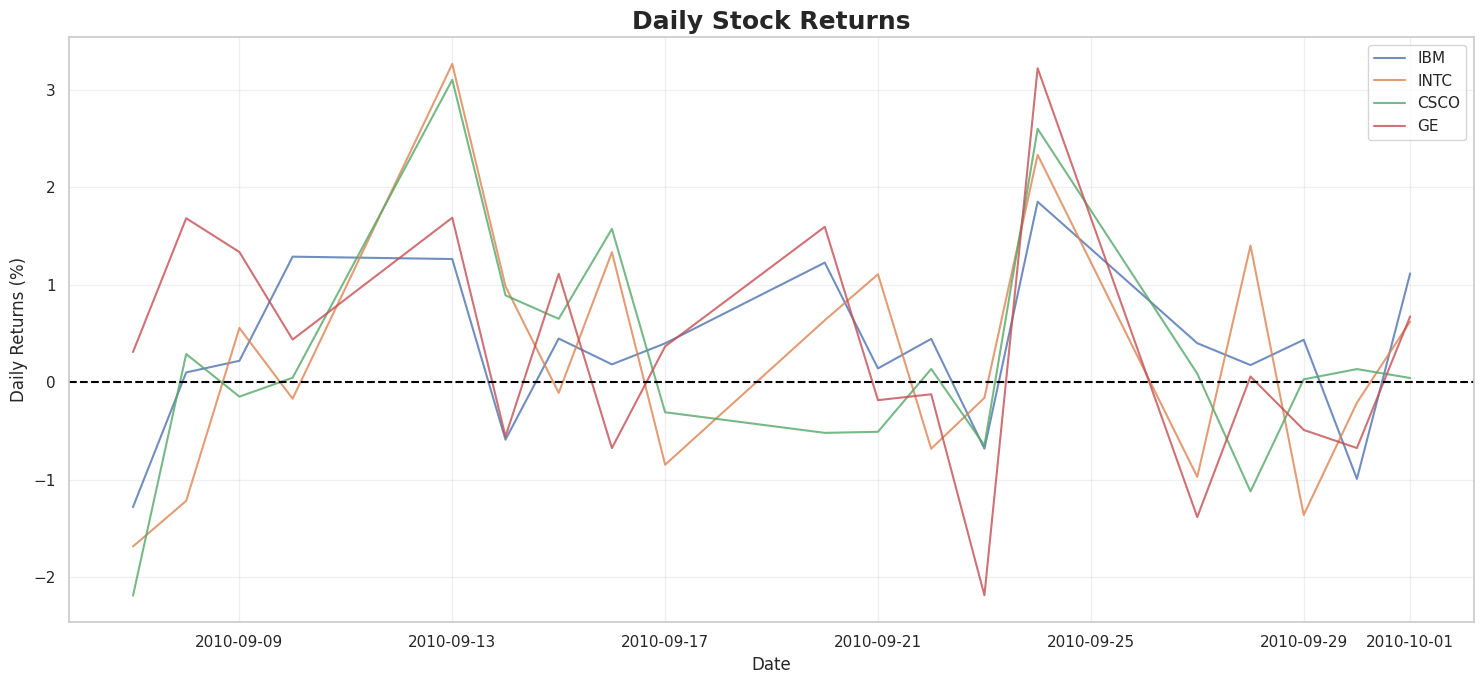

In [ ]:
# Calculate daily percentage returns
returns = price_data.pct_change(
    fill_method=None
) * 100

plt.figure(figsize=(15, 7))

for stock in stocks:
    plt.plot(
        returns.index,
        returns[stock],
        label=stock,
        alpha=0.8
    )

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.title(
    "Daily Stock Returns",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Daily Returns (%)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

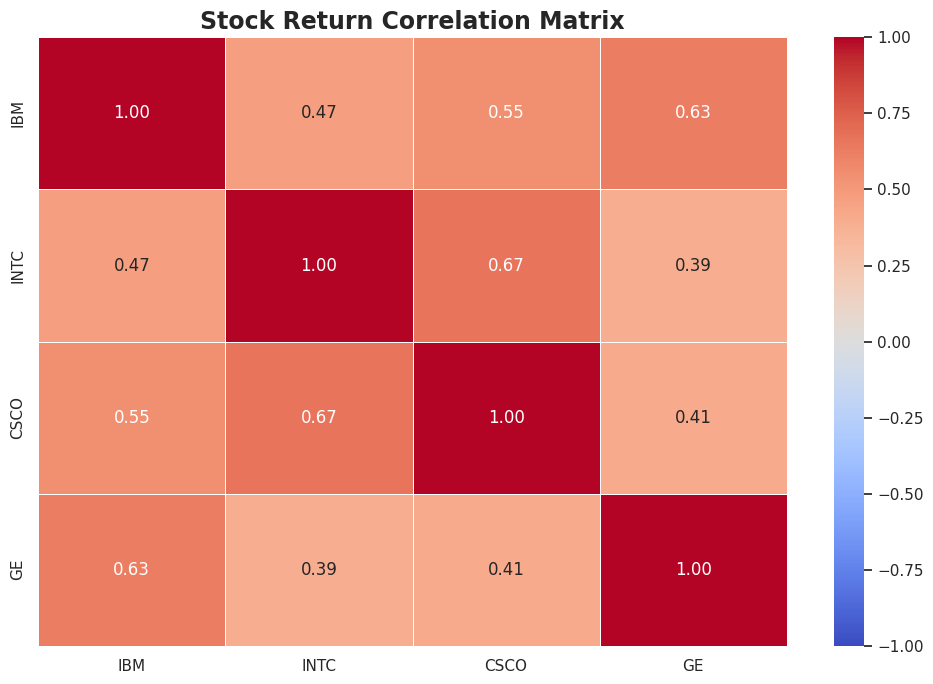

In [ ]:
# Calculate correlation matrix
correlation = returns.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title(
    "Stock Return Correlation Matrix",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

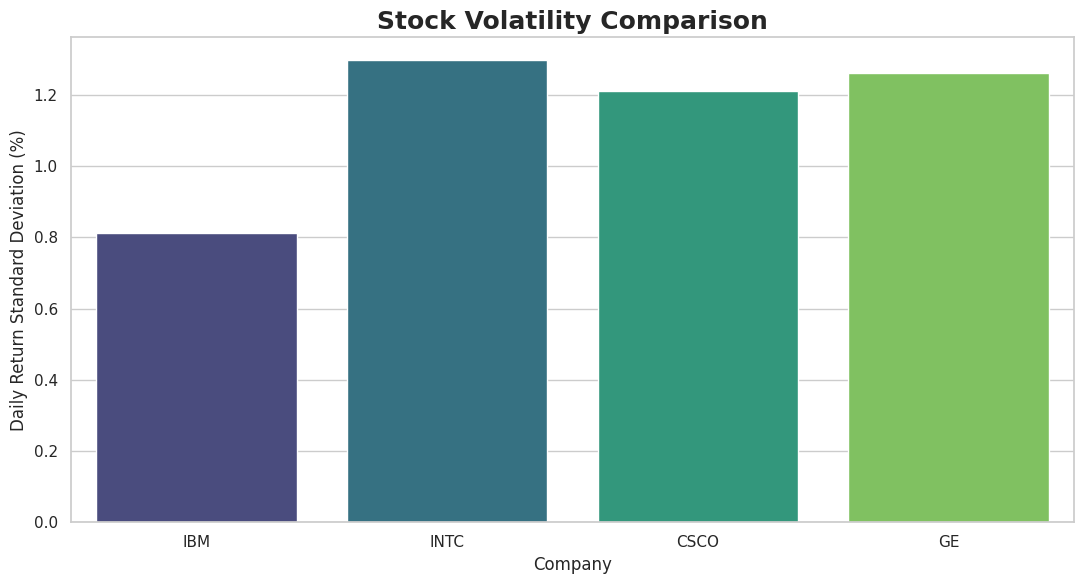

Daily Volatility:


,0
INTC,1.297464
GE,1.261456
CSCO,1.211064
IBM,0.813761


In [ ]:
# Calculate daily volatility
volatility = returns.std()

plt.figure(figsize=(11, 6))

sns.barplot(
    x=volatility.index,
    y=volatility.values,
    hue=volatility.index,
    palette="viridis",
    legend=False
)

plt.title(
    "Stock Volatility Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Company")
plt.ylabel("Daily Return Standard Deviation (%)")

plt.tight_layout()
plt.show()

print("Daily Volatility:")
display(volatility.sort_values(ascending=False))

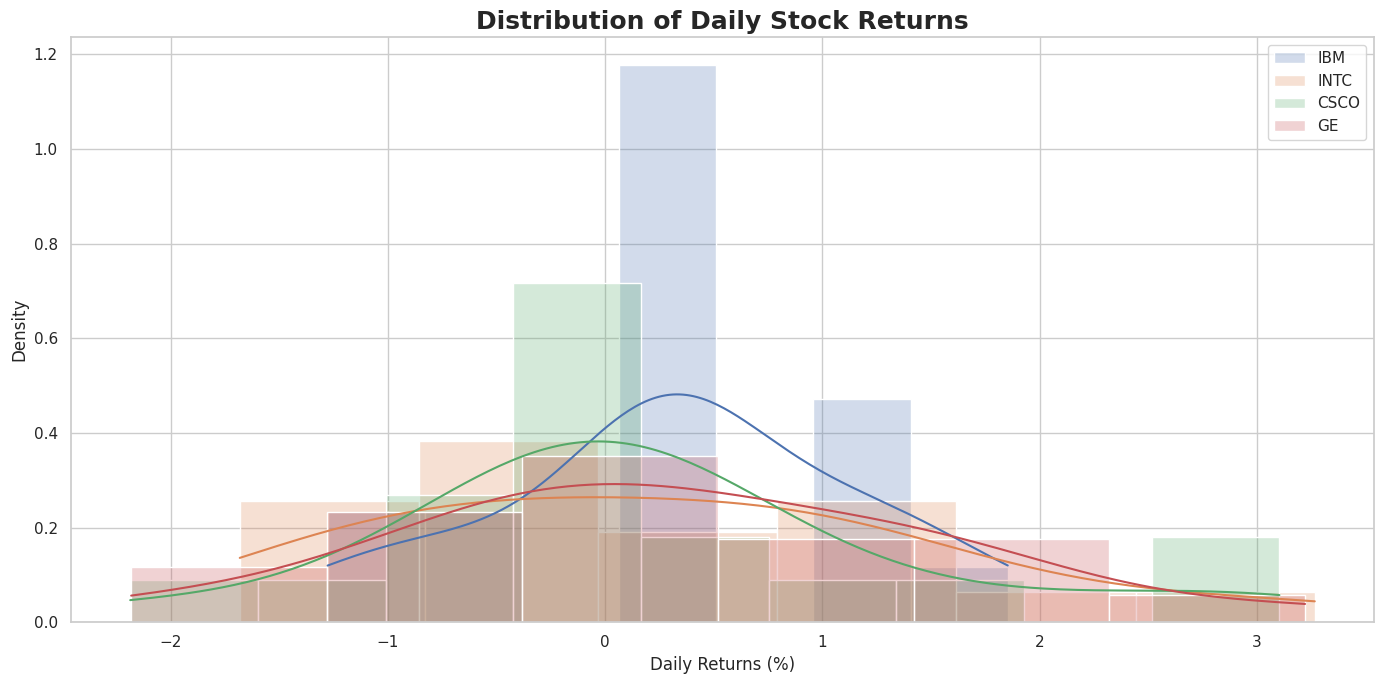

In [ ]:
plt.figure(figsize=(14, 7))

for stock in stocks:
    sns.histplot(
        returns[stock].dropna(),
        kde=True,
        stat="density",
        alpha=0.25,
        label=stock
    )

plt.title(
    "Distribution of Daily Stock Returns",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Daily Returns (%)")
plt.ylabel("Density")

plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# Reshape dataset
df_long = df.melt(
    id_vars="Date",
    value_vars=stocks,
    var_name="Company",
    value_name="Closing Price"
)

# Create interactive chart
fig = px.line(
    df_long,
    x="Date",
    y="Closing Price",
    color="Company",
    title="Interactive Stock Market Dashboard",
    template="plotly_dark"
)

fig.update_layout(
    title_font_size=22,
    xaxis_title="Trading Date",
    yaxis_title="Closing Stock Price",
    hovermode="x unified",
    height=650
)

fig.show()

In [14]:
# Average daily returns
average_returns = returns.mean()

# Daily volatility
daily_volatility = returns.std()

# Total percentage returns
total_returns = (
    price_data.apply(lambda col: col.dropna().iloc[-1])
    /
    price_data.apply(lambda col: col.dropna().iloc[0])
    - 1
) * 100

# Create summary table
summary = pd.DataFrame({
    "Average Daily Return (%)": average_returns,
    "Daily Volatility (%)": daily_volatility,
    "Total Return (%)": total_returns
})

# Round results
summary = summary.round(3)

print("STOCK MARKET PERFORMANCE SUMMARY")

display(summary)

STOCK MARKET PERFORMANCE SUMMARY


,Average Daily Return (%),Daily Volatility (%),Total Return (%)
IBM,0.326,0.814,6.318
INTC,0.256,1.297,4.829
CSCO,0.220,1.211,4.135
GE,0.329,1.261,6.289


In [15]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=summary)

https://docs.google.com/spreadsheets/d/1uhQFZP8cnoPQOJsPbEOIkZUelcn1b9H9hAEud_oh7wA/edit#gid=0


In [16]:
fig.write_html(
    "Interactive_Stock_Dashboard.html"
)

files.download(
    "Interactive_Stock_Dashboard.html"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>